# Практикум. Повнозв’язні нейронні мережі в TensorFlow/Keras

**Тема:** будова нейрона, функції активації, шари `Dense`, `Flatten`, `BatchNormalization`, `Dropout`, навчання, оптимізатори та оцінювання багатокласової класифікації.

**Мета роботи:** самостійно простежити шлях від одного штучного нейрона до повноцінної моделі класифікації, навчитися аналізувати криві навчання, архітектуру та порівнювати справжні й прогнозовані класи.

У **розділах 1–9** наведено виконувані приклади з коментарями. **Розділ 10** — самостійне завдання, у якому комірки для коду та висновку залишено порожніми.

> **Межі практикуму.** Розглядаємо лише повнозв’язні нейронні мережі (MLP). Згорткові мережі (CNN) вивчатимуться окремо.

## Перед початком роботи

Рекомендоване середовище — **Jupyter Notebook, JupyterLab або Google Colab** з Python та TensorFlow 2.x. Для встановлення необхідних бібліотек за потреби виконайте у **новій** комірці:

```python
%pip install tensorflow numpy matplotlib scikit-learn pydot
```

Для графічного представлення архітектури через `plot_model()` додатково може знадобитися **системний Graphviz**. Водночас `model.summary()` працює без нього. Навчальний набір `digits` є частиною `scikit-learn` і не потребує завантаження з інтернету.

Комірки виконуйте **послідовно зверху вниз**. Після змін у моделі за потреби повторно виконайте комірки створення, компіляції та навчання.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

keras.utils.set_random_seed(42)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__ if hasattr(keras, "__version__") else "tf.keras")
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
Keras: 3.15.1
NumPy: 2.5.5


## 1. Як працює штучний нейрон

Нейрон отримує вхідний вектор ознак $\mathbf{x}$, множить кожну ознаку на відповідну вагу, додає зсув $b$ та застосовує функцію активації $f$:

$$
z = \sum_{i=1}^{n}w_i x_i + b, \qquad a=f(z).
$$

Ваги $w_i$ і зсув $b$ є **навчуваними параметрами**. Функція активації додає нелінійність. У прикладі нижче використано $x=(2,1)$, $w=(0{,}5,-1)$, $b=0{,}2$ і функцію ReLU. Очікуваний результат: $z=0{,}2$, $a=0{,}2$.

In [ ]:
x = np.array([2.0, 1.0])
w = np.array([0.5, -1.0])
b = 0.2

z = np.dot(x, w) + b
activation = np.maximum(0.0, z)  # ReLU(z) = max(0, z)

print(f"Зважена сума: z = {z:.2f}")
print(f"Вихід нейрона: a = {activation:.2f}")
assert np.isclose(z, 0.2)

Зважена сума: z = 0.20
Вихід нейрона: a = 0.20


## 2. Функції активації

Для прихованих шарів часто обирають **ReLU**: $f(z)=\max(0,z)$. Функція **sigmoid** повертає число в діапазоні $(0,1)$, а **tanh** — у діапазоні $(-1,1)$:

$$
\sigma(z)=\frac{1}{1+e^{-z}}, \qquad \tanh(z)=\frac{e^z-e^{-z}}{e^z+e^{-z}}.
$$

Для класифікації **одного з кількох взаємовиключних класів** на виході зручно застосовувати **softmax**:

$$
\operatorname{softmax}(z)_i=\frac{e^{z_i}}{\sum_j e^{z_j}}.
$$

Після softmax отримуємо невід’ємні оцінки ймовірностей, сума яких дорівнює одиниці. У цьому практикумі приховані шари використовуватимуть ReLU, а вихідний — softmax.

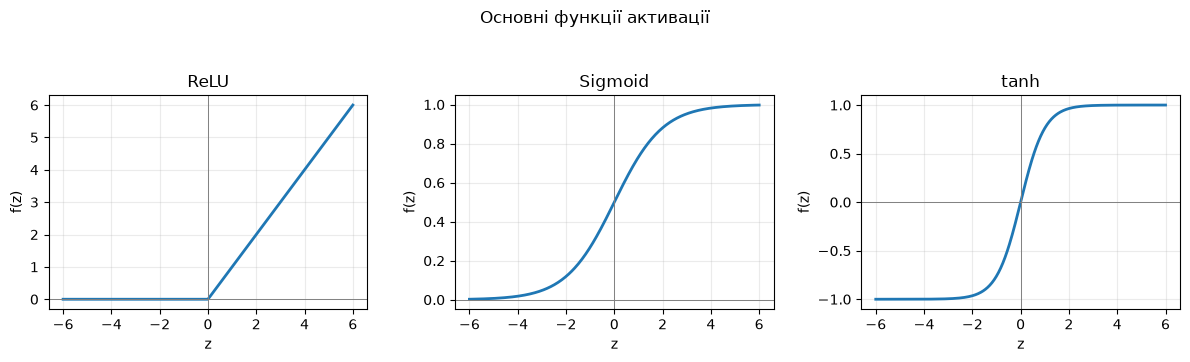

In [ ]:
z_values = np.linspace(-6, 6, 400)
activation_functions = {
    "ReLU": np.maximum(0, z_values),
    "Sigmoid": 1 / (1 + np.exp(-z_values)),
    "tanh": np.tanh(z_values),
}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (name, values) in zip(axes, activation_functions.items()):
    ax.plot(z_values, values, linewidth=2)
    ax.axhline(0, color="gray", linewidth=0.7)
    ax.axvline(0, color="gray", linewidth=0.7)
    ax.set_title(name)
    ax.set_xlabel("z")
    ax.set_ylabel("f(z)")
    ax.grid(alpha=0.25)
plt.suptitle("Основні функції активації", y=1.05)
plt.tight_layout()
plt.show()

## 3. Набір даних для класифікації

Працюватимемо з **`digits`** із `scikit-learn`: 1797 зображень рукописних цифр розміром **8 × 8** пікселів. Класи позначено числами **0–9**. Значення яскравості пікселів спочатку лежать у діапазоні 0–16.

Кожному зображенню відповідає правильна мітка $y$. Перш ніж будувати модель, важливо перевірити структуру даних і побачити кілька прикладів.

Форма масиву зображень: (1797, 8, 8)
Форма масиву міток: (1797,)
Класи: [0 1 2 3 4 5 6 7 8 9]
Діапазон пікселів: 0.0 — 16.0


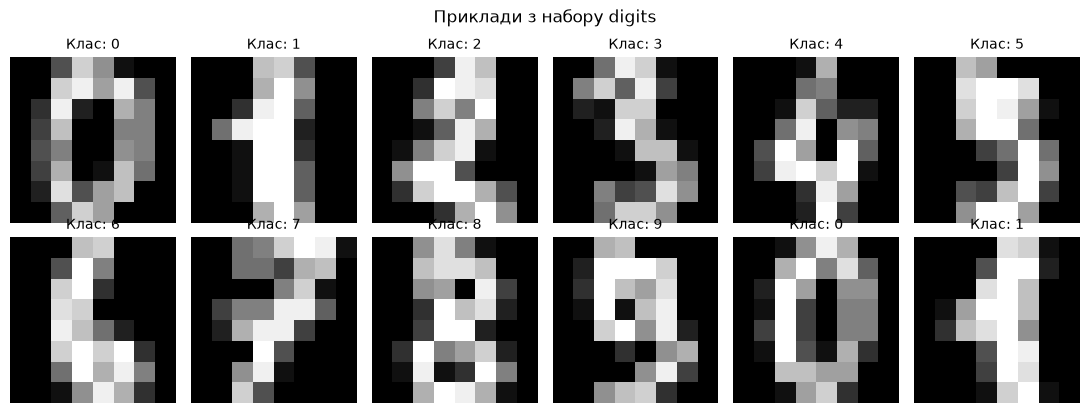

In [ ]:
digits = load_digits()
images = digits.images
labels = digits.target

print("Форма масиву зображень:", images.shape)
print("Форма масиву міток:", labels.shape)
print("Класи:", np.unique(labels))
print("Діапазон пікселів:", images.min(), "—", images.max())

fig, axes = plt.subplots(2, 6, figsize=(11, 4.2))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap="gray", vmin=0, vmax=16)
    ax.set_title(f"Клас: {labels[i]}", fontsize=10)
    ax.axis("off")
plt.suptitle("Приклади з набору digits")
plt.tight_layout()
plt.show()

### Підготовка та поділ даних

Поділимо зображення на **навчальну**, **валідаційну** та **тестову** вибірки. Навчальна вибірка потрібна для оновлення ваг, валідаційна — для спостереження за якістю під час навчання, тестова — для завершальної незалежної оцінки. Параметр `stratify` допомагає зберегти співвідношення класів.

Пікселі нормалізуємо за формулою $x_{norm}=x/16$, тобто приведемо до діапазону $[0,1]$.

In [ ]:
x_all = images.astype("float32") / 16.0
y_all = labels.astype("int64")

# 80% даних — для навчання + валідації; 20% — тест
x_trainval, x_test, y_trainval, y_test = train_test_split(
    x_all, y_all, test_size=0.20, random_state=42, stratify=y_all
)

# Із trainval виділяємо 20% для валідації
x_train, x_val, y_train, y_val = train_test_split(
    x_trainval, y_trainval, test_size=0.20,
    random_state=42, stratify=y_trainval
)

for name, x_part, y_part in [
    ("Навчальна", x_train, y_train),
    ("Валідаційна", x_val, y_val),
    ("Тестова", x_test, y_test),
]:
    print(f"{name:12s}: x={x_part.shape}, y={y_part.shape}")

assert np.all((x_train >= 0) & (x_train <= 1))
assert x_train.shape[1:] == (8, 8)
assert len(np.unique(y_train)) == 10

Навчальна   : x=(1149, 8, 8), y=(1149,)
Валідаційна : x=(288, 8, 8), y=(288,)
Тестова     : x=(360, 8, 8), y=(360,)


## 4. Архітектура повнозв’язної нейронної мережі

**Повнозв’язний шар (`Dense`)** означає, що кожний його нейрон отримує виходи всіх нейронів попереднього шару. Для матриці входів $X$ та ваг $W$ виконується перетворення

$$
H=f(XW+b).
$$

Ми використаємо такі шари:

- `Flatten` — перетворює зображення $8\times 8$ на вектор із 64 ознак (без навчуваних параметрів).
- `Dense(64)` — перший повнозв’язний шар.
- `BatchNormalization` — нормалізує проміжні активації; зберігає навчувані коефіцієнти масштабу та зміщення.
- `Activation("relu")` — задає нелінійність.
- `Dropout(0.2)` — під час навчання випадково зануляє приблизно 20% активацій для регуляризації.
- `Dense(32)` — другий повнозв’язний шар.
- `Dense(10, activation="softmax")` — повертає десять оцінок належності до класів.

Під час **передбачення** (`predict`) `Dropout` не вимикає нейрони випадковим чином; `BatchNormalization` використовує накопичені статистики.

In [ ]:
model = keras.Sequential([
    keras.Input(shape=(8, 8), name="image"),
    layers.Flatten(name="flatten"),
    layers.Dense(64, use_bias=False, name="dense_64"),
    layers.BatchNormalization(name="batch_norm"),
    layers.Activation("relu", name="relu"),
    layers.Dropout(0.20, name="dropout"),
    layers.Dense(32, activation="relu", name="dense_32"),
    layers.Dense(10, activation="softmax", name="classes"),
], name="digits_mlp")

model.summary()
print("Всього параметрів:", model.count_params())

Model: "digits_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm (BatchNormalization) │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu (Activation)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classes (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,762 (26.41 KB)

 Trainable params: 6,634 (25.91 KB)

 Non-trainable params: 128 (512.00 B)

Всього параметрів: 6762


### Як читати `model.summary()`

Таблиця `summary()` показує **назву шару**, **форму виходу** та **кількість параметрів**. Для `Dense` кількість параметрів дорівнює $n_{in}\cdot n_{out}+n_{out}$, якщо використовується зсув `bias`; без нього — $n_{in}\cdot n_{out}$.

У нашій моделі перший `Dense` без зсуву має $64\cdot64=4096$ параметрів; наступний `Dense(32)` має $64\cdot32+32=2080$, а вихідний — $32\cdot10+10=330$. `BatchNormalization` додає власні параметри та статистики.

Схему мережі можна зберегти через `keras.utils.plot_model()`. Наступна комірка **необов’язкова**: якщо Graphviz або `pydot` не встановлено, навчання все одно працюватиме.

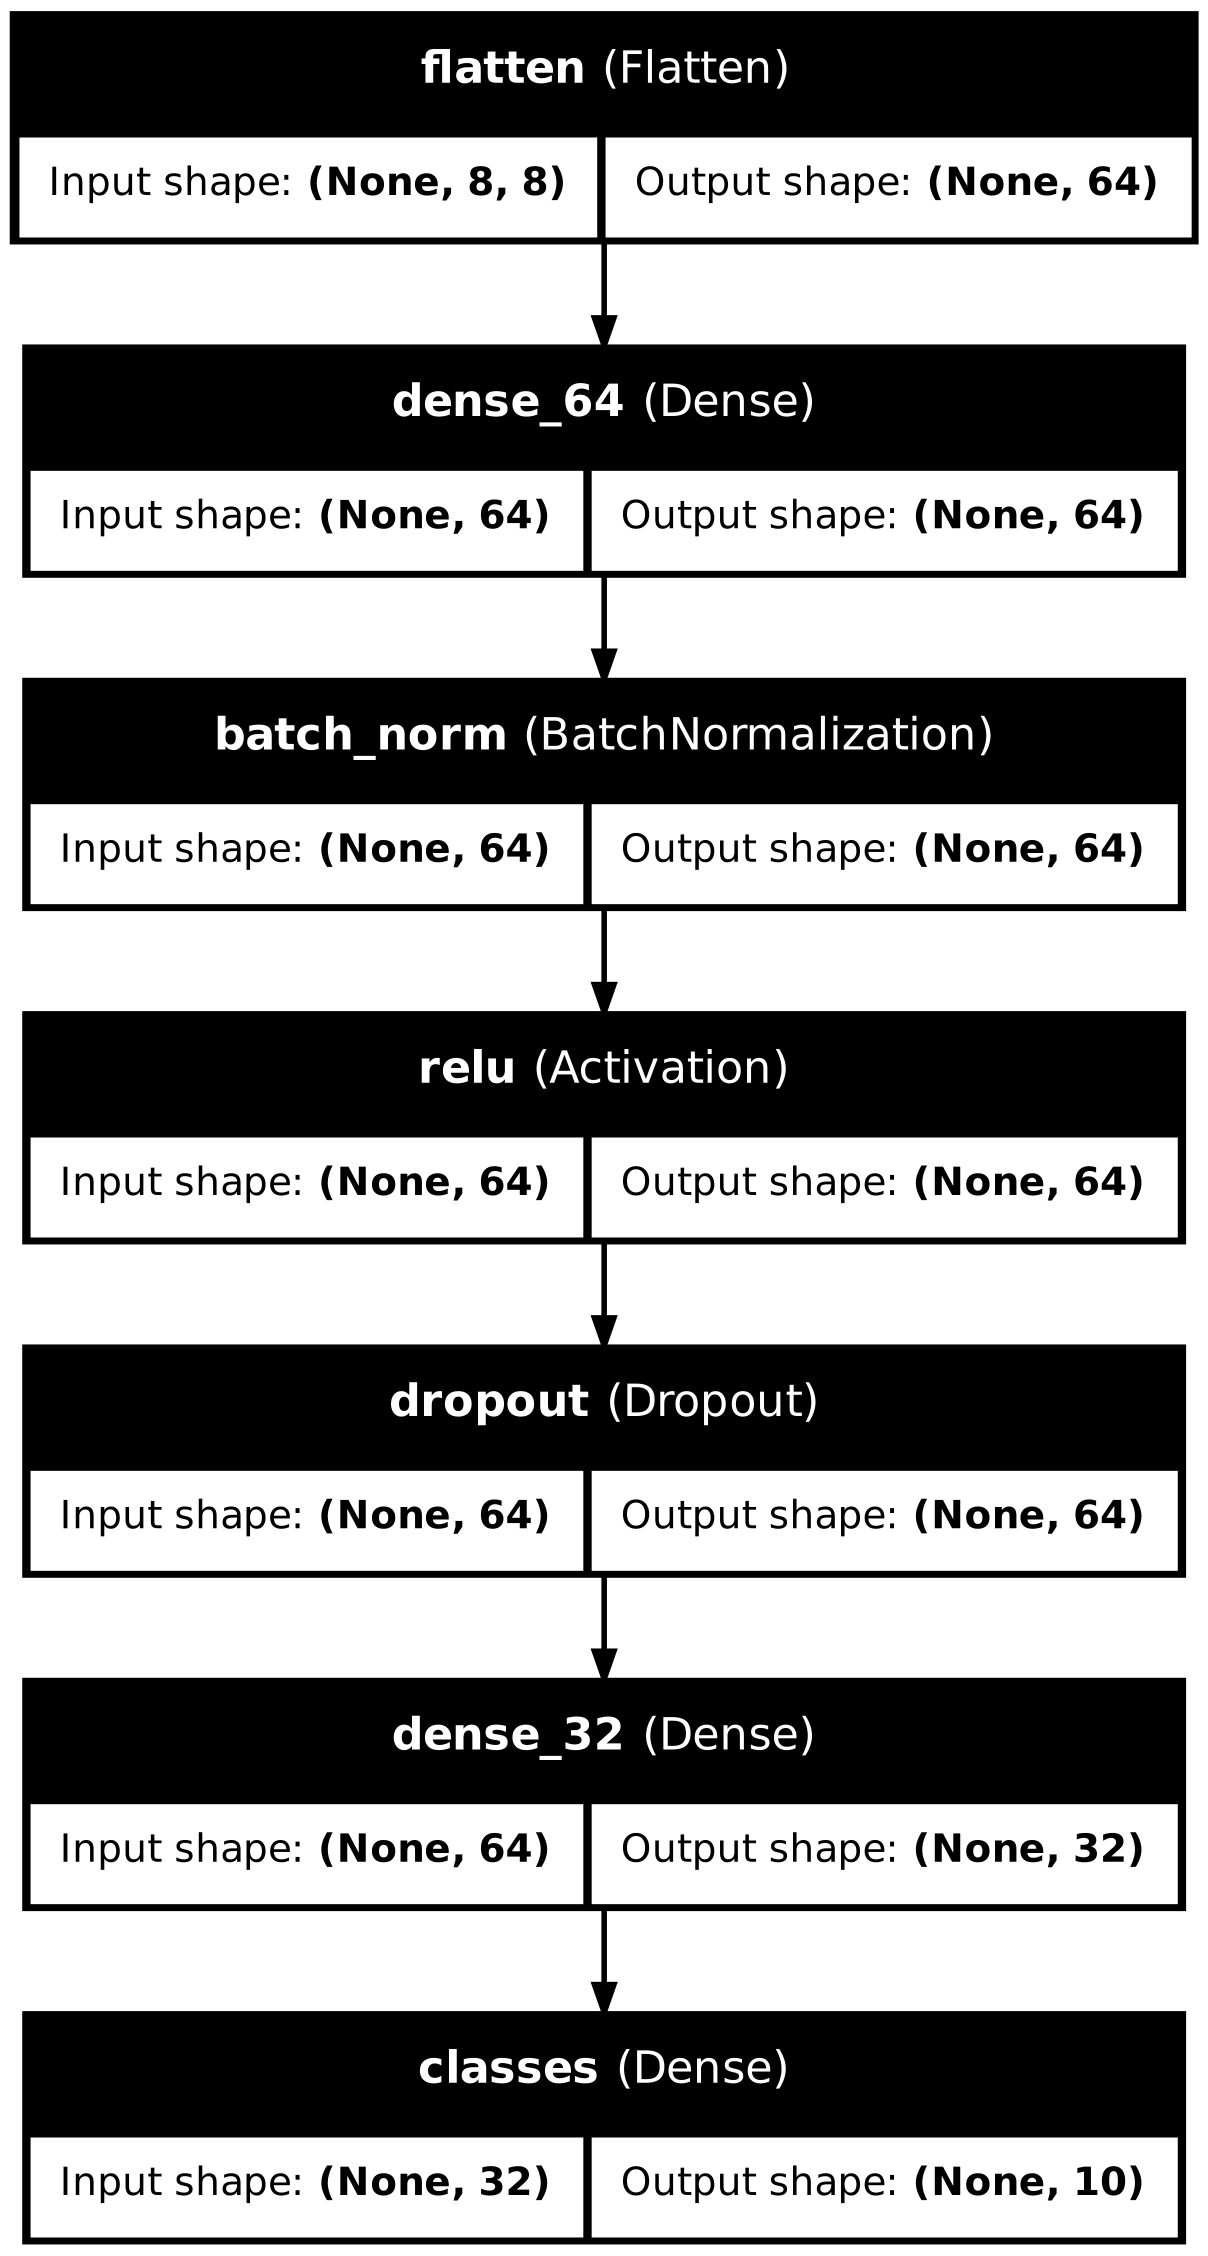

In [ ]:
try:
    from IPython.display import Image, display

    keras.utils.plot_model(
        model,
        to_file="digits_mlp_architecture.png",
        show_shapes=True,
        show_layer_names=True,
        rankdir="TB",
    )
    display(Image(filename="digits_mlp_architecture.png"))
except Exception as exc:
    print("Графічна схема недоступна; скористайтеся model.summary().")
    print("Причина:", type(exc).__name__, str(exc)[:250])

## 5. Функція втрат, оптимізатори та компіляція

Під час навчання мережа прогнозує клас, а **функція втрат** оцінює невідповідність між прогнозом і правильною міткою. Градієнти обчислюються автоматично за алгоритмом **зворотного поширення помилки** (backpropagation). Оптимізатор оновлює ваги у напрямі зменшення втрат.

Для звичайного градієнтного спуску крок оновлення має вигляд:

$$
w_{t+1}=w_t-\eta\nabla_w L(w_t),
$$

де $\eta$ — швидкість навчання (*learning rate*).

**SGD** виконує градієнтні оновлення, **Adam** адаптує масштаб кроків для різних параметрів, а **AdamW** додатково реалізує відокремлене зменшення ваг (*weight decay*). Тут візьмемо `Adam(learning_rate=0.001)`.

Для **10 класів із цілочисельними мітками** підходить `SparseCategoricalCrossentropy`. Метрика `accuracy` — частка правильних відповідей.

In [ ]:
# Приклади альтернатив (для ознайомлення):
sgd_optimizer = keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
adam_optimizer = keras.optimizers.Adam(learning_rate=0.001)

model.compile(
    optimizer=adam_optimizer,
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

print("Оптимізатор моделі:", type(model.optimizer).__name__)
print("Функція втрат: SparseCategoricalCrossentropy")

Оптимізатор моделі: Adam
Функція втрат: SparseCategoricalCrossentropy


## 6. Навчання моделі

Метод `fit()` здійснює багаторазове проходження навчальної вибірки. **Епоха** — один повний прохід, а **пакет (batch)** — частина прикладів, за якою виконується чергове оновлення ваг.

Після кожної епохи Keras обчислює `val_loss` і `val_accuracy`. **EarlyStopping** припиняє навчання, якщо валідаційні втрати не поліпшуються протягом кількох епох, і може повернути найкращі ваги.

In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1,
)

print("Фактична кількість епох:", len(history.history["loss"]))

Epoch 1/30


 1/36 ━━━━━━━━━━━━━━━━━━━━ 20s 589ms/step - accuracy: 0.0938 - loss: 2.7254

36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.3238 - loss: 2.0187 - val_accuracy: 0.4340 - val_loss: 1.9900


Epoch 2/30


 1/36 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4688 - loss: 1.6432

36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6675 - loss: 1.2706 - val_accuracy: 0.8229 - val_loss: 1.5783


... (65 outputs left out)

 1/36 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 1.0000 - loss: 0.0272

33/36 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9905 - loss: 0.0402 

36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9904 - loss: 0.0408 - val_accuracy: 0.9757 - val_loss: 0.0710


Фактична кількість епох: 24


## 7. Криві навчання: втрати та точність

Об’єкт `history` містить історію значень **`loss`**, **`val_loss`**, **`accuracy`**, **`val_accuracy`**. На графіку слід порівняти не лише кінцеві значення, а й динаміку:

- якщо обидві точності низькі — можливе **недонавчання**;
- якщо навчальна точність висока, а валідаційна значно нижча — можливе **перенавчання**;
- якщо валідаційна помилка стабілізується, а навчальна продовжує падати — доцільно перевірити регуляризацію й момент зупинки.

Через відмінності в режимах роботи Dropout/BatchNormalization валідаційні показники іноді можуть бути кращими за навчальні; сам по собі такий випадок не є помилкою.

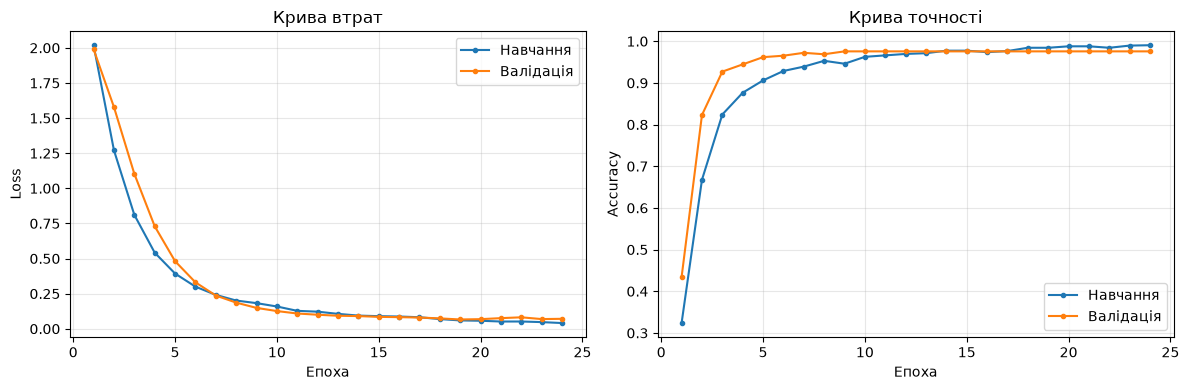

In [ ]:
epochs_done = np.arange(1, len(history.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_done, history.history["loss"], label="Навчання", marker="o", ms=3)
axes[0].plot(epochs_done, history.history["val_loss"], label="Валідація", marker="o", ms=3)
axes[0].set(title="Крива втрат", xlabel="Епоха", ylabel="Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_done, history.history["accuracy"], label="Навчання", marker="o", ms=3)
axes[1].plot(epochs_done, history.history["val_accuracy"], label="Валідація", marker="o", ms=3)
axes[1].set(title="Крива точності", xlabel="Епоха", ylabel="Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Оцінювання та візуалізація класифікації

Після навчання один раз оцінюємо модель на **тестовій вибірці**, яка не використовувалася ні для навчання, ні для підбору параметрів. Метод `evaluate()` поверне втрати й точність, а `predict()` — вектор із 10 значень softmax для кожного зображення.

Щоб отримати номер прогнозованого класу, застосуємо `np.argmax(..., axis=1)`. Далі покажемо зображення з підписами **«Справжній клас»** і **«Прогноз»**. Зеленим виділимо правильні відповіді, червоним — помилки.

In [ ]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
probabilities = model.predict(x_test, verbose=0)
predicted_classes = np.argmax(probabilities, axis=1)
confidence = probabilities.max(axis=1)

print(f"Тестові втрати: {test_loss:.4f}")
print(f"Тестова точність: {test_accuracy:.2%}")
print(f"Правильно: {(predicted_classes == y_test).sum()} із {len(y_test)}")
print("Форма прогнозів:", probabilities.shape)
assert probabilities.shape == (len(x_test), 10)

Тестові втрати: 0.0679
Тестова точність: 97.78%
Правильно: 352 із 360
Форма прогнозів: (360, 10)


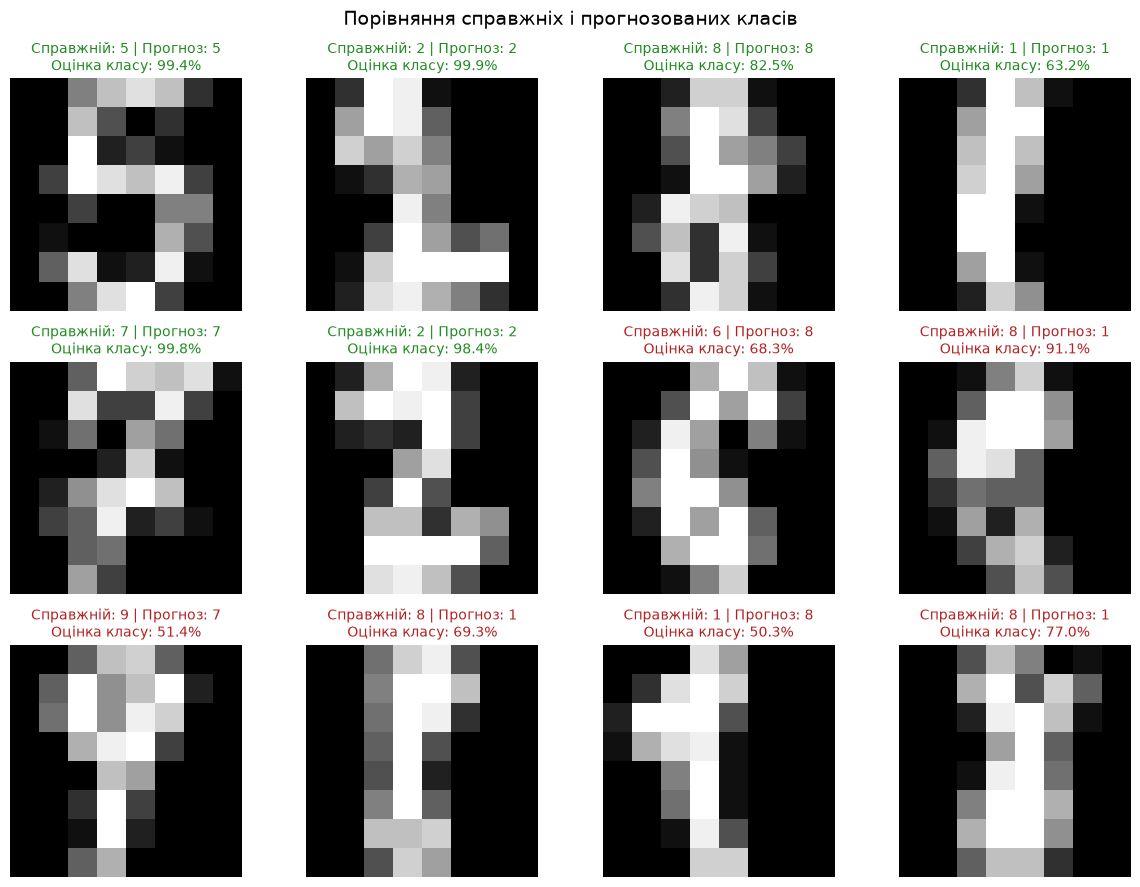

In [ ]:
correct_idx = np.flatnonzero(predicted_classes == y_test)
wrong_idx = np.flatnonzero(predicted_classes != y_test)

# До 6 правильних і до 6 помилкових прикладів; решту місць доповнюємо правильними
selected = list(correct_idx[:6]) + list(wrong_idx[:6])
if len(selected) < 12:
    selected += list(correct_idx[6:6 + (12 - len(selected))])

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, idx in zip(axes.flat, selected):
    is_correct = predicted_classes[idx] == y_test[idx]
    color = "forestgreen" if is_correct else "firebrick"
    ax.imshow(x_test[idx], cmap="gray", vmin=0, vmax=1)
    ax.set_title(
        f"Справжній: {y_test[idx]} | Прогноз: {predicted_classes[idx]}\n"
        f"Оцінка класу: {confidence[idx]:.1%}",
        color=color,
        fontsize=10,
    )
    ax.axis("off")
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor(color)
        spine.set_linewidth(2)
for ax in axes.flat[len(selected):]:
    ax.axis("off")
plt.suptitle("Порівняння справжніх і прогнозованих класів", fontsize=14)
plt.tight_layout()
plt.show()

### Матриця помилок і детальні метрики

**Матриця помилок** показує, які класи плутаються між собою. У рядках розташовано **справжні** класи, у стовпцях — **прогнозовані**. Крім accuracy, корисно переглядати **precision**, **recall** і **F1-score** для кожного класу.

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        36
           1      0.921     0.972     0.946        36
           2      0.946     1.000     0.972        35
           3      1.000     1.000     1.000        37
           4      1.000     1.000     1.000        36
           5      1.000     1.000     1.000        37
           6      1.000     0.972     0.986        36
           7      0.973     1.000     0.986        36
           8      0.938     0.857     0.896        35
           9      1.000     0.972     0.986        36

    accuracy                          0.978       360
   macro avg      0.978     0.977     0.977       360
weighted avg      0.978     0.978     0.978       360



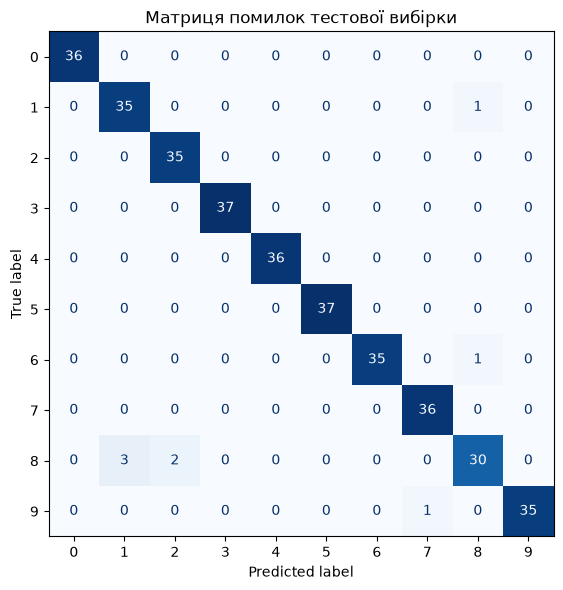

In [ ]:
print(classification_report(y_test, predicted_classes, digits=3, zero_division=0))

matrix = confusion_matrix(y_test, predicted_classes, labels=np.arange(10))
display_matrix = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=np.arange(10))
fig, ax = plt.subplots(figsize=(7, 6))
display_matrix.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Матриця помилок тестової вибірки")
plt.tight_layout()
plt.show()

## 9. Збереження та відновлення навченої моделі

Формат **`.keras`** дає змогу зберегти архітектуру, параметри та стан моделі. Після завантаження перевіримо, що результати прогнозування збігаються з результатами вихідної моделі. Передоброблення нових даних має бути таким самим, як під час навчання (у нашому випадку — ділення пікселів на 16).

In [ ]:
model.save("digits_mlp.keras")
restored_model = keras.models.load_model("digits_mlp.keras")

original_predictions = model.predict(x_test[:5], verbose=0)
restored_predictions = restored_model.predict(x_test[:5], verbose=0)
np.testing.assert_allclose(original_predictions, restored_predictions, atol=1e-6, rtol=1e-5)

print("Модель збережено до digits_mlp.keras і успішно відновлено.")

Модель збережено до digits_mlp.keras і успішно відновлено.


### Контрольні запитання до виконаних прикладів

1. Для чого шар `Flatten` потрібний перед `Dense` у нашій моделі?
2. Чому для десяти взаємовиключних класів використано `softmax`?
3. Чим відрізняється `loss` від `accuracy`, а `val_loss` — від `loss`?
4. Чому тестову вибірку не використовують для налаштування архітектури?
5. Що означає кількість параметрів у `model.summary()`?
6. Чому `Dropout` по-різному поводиться під час `fit()` та `predict()`?

Наведені вище приклади повністю виконувані. Наступне завдання необхідно реалізувати **самостійно**.

**Відповіді на контрольні запитання:**

1. **`Flatten`** перетворює зображення $8\times 8$ на вектор із 64 чисел. Шар `Dense` працює з одновимірним вектором ознак на кожен приклад: він множить вектор на матрицю ваг $W$ розміром $64\times n_{out}$. Сам `Flatten` параметрів не має.
2. **`softmax`** перетворює 10 виходів на невід'ємні числа із сумою 1, тобто на розподіл ймовірностей між класами. Для взаємовиключних класів саме це і потрібно: зображення належить рівно до одного класу, тож прогнозом є клас із найбільшою ймовірністю (`argmax`), а `SparseCategoricalCrossentropy` порівнює цей розподіл із правильною міткою.
3. **`loss`** — це значення функції втрат (крос-ентропії). Воно неперервне й враховує впевненість моделі, тому саме його мінімізує оптимізатор. **`accuracy`** — частка правильних відповідей, її зручно інтерпретувати, але вона не диференційовна. `loss` обчислюється на навчальній вибірці (з увімкненим Dropout), а **`val_loss`** — на валідаційній, яка не бере участі в оновленні ваг; порівняння цих двох величин показує перенавчання.
4. **Тестову вибірку** не використовують для налаштування архітектури, бо тоді модель і гіперпараметри неявно підлаштуються під неї. Тестова оцінка стане завищеною і перестане бути незалежною перевіркою на нових даних. Для вибору налаштувань служить валідаційна вибірка.
5. **Кількість параметрів** у `summary()` — це кількість чисел, які зберігає модель: ваги та зсуви `Dense`, коефіцієнти $\gamma$, $\beta$ і статистики BatchNormalization. Навчувані параметри оновлюються оптимізатором, а ненавчувані (ковзні середнє та дисперсія BN) лише накопичуються. Кількість параметрів характеризує складність моделі та ризик перенавчання.
6. **`Dropout`** під час `fit()` випадково зануляє частину активацій (і масштабує решту на $1/(1-rate)$), щоб мережа не покладалася на окремі нейрони — це регуляризація. Під час `predict()` потрібен детермінований і найточніший прогноз, тому всі нейрони працюють, а завдяки масштабуванню на етапі навчання очікуване значення активацій не змінюється.

---

# 10. Самостійне завдання — заповнити порожні комірки

**Завдання.** Створіть **нову повнозв’язну модель** для тих самих зображень `digits`, навчіть її та порівняйте з базовою моделлю `model`. Результат має містити **архітектуру**, **криві навчання**, **тестові метрики**, **зображення зі справжніми та прогнозованими класами** й **короткий висновок**.

**Вимоги до нового варіанта:**

- використайте `Flatten` і щонайменше два приховані шари `Dense`, наприклад **128 і 64 нейрони**;
- застосуйте `ReLU`, `BatchNormalization` та `Dropout` зі значенням `rate=0.30`;
- сформуйте вихід із **10 нейронів та softmax**;
- оберіть **SGD з momentum** або **AdamW**, поясніть свій вибір;
- навчайте до **25 епох**, використовуючи `EarlyStopping`;
- не змінюйте тестові мітки і не тренуйте модель на `x_test`.

**Орієнтовне оцінювання — 10 балів:** архітектура й `summary()` — 2; коректна компіляція та навчання — 2; криві — 2; оцінка та візуалізація прогнозів — 2; обґрунтований висновок — 2.

Нижче навмисно залишено **порожні комірки без розв’язків**. Заповніть їх власним кодом.

### Крок 1. Створіть нову модель

Використайте **нову змінну `student_model`** (не перезаписуйте базову `model`), додайте шари за умовою та виведіть її архітектуру через `summary()`.

In [ ]:
# Фіксуємо seed, щоб нова модель ініціалізувалась відтворювано
keras.utils.set_random_seed(42)


def build_student_model(dropout_rate=0.30, name="student_mlp"):
    """Повнозв'язна мережа: Flatten → [Dense → BN → ReLU → Dropout] × 2 → Dense(10, softmax)."""
    return keras.Sequential([
        keras.Input(shape=(8, 8), name="image"),
        layers.Flatten(name="flatten"),

        # Перший прихований блок: 128 нейронів
        layers.Dense(128, use_bias=False, name="dense_128"),   # зсув не потрібен: його замінює beta у BN
        layers.BatchNormalization(name="batch_norm_1"),
        layers.Activation("relu", name="relu_1"),
        layers.Dropout(dropout_rate, name="dropout_1"),

        # Другий прихований блок: 64 нейрони
        layers.Dense(64, use_bias=False, name="dense_64"),
        layers.BatchNormalization(name="batch_norm_2"),
        layers.Activation("relu", name="relu_2"),
        layers.Dropout(dropout_rate, name="dropout_2"),

        # Вихідний шар: 10 класів
        layers.Dense(10, activation="softmax", name="classes"),
    ], name=name)


student_model = build_student_model(dropout_rate=0.30)
student_model.summary()

trainable = int(sum(np.prod(w.shape) for w in student_model.trainable_weights))
non_trainable = int(sum(np.prod(w.shape) for w in student_model.non_trainable_weights))
print(f"Усього параметрів: {student_model.count_params()} "
      f"(навчуваних: {trainable}, ненавчуваних статистик BN: {non_trainable})")
print(f"Базова модель: {model.count_params()} параметрів")

# Перевірка ручного підрахунку: 64·128 + 128·64 + (64·10 + 10) + BN: 4·128 + 4·64
assert student_model.count_params() == 64 * 128 + 128 * 64 + (64 * 10 + 10) + 4 * 128 + 4 * 64

Model: "student_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1                    │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (Activation)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_2                    │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (Activation)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classes (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,802 (69.54 KB)

 Trainable params: 17,418 (68.04 KB)

 Non-trainable params: 384 (1.50 KB)

Усього параметрів: 17802 (навчуваних: 17418, ненавчуваних статистик BN: 384)
Базова модель: 6762 параметрів


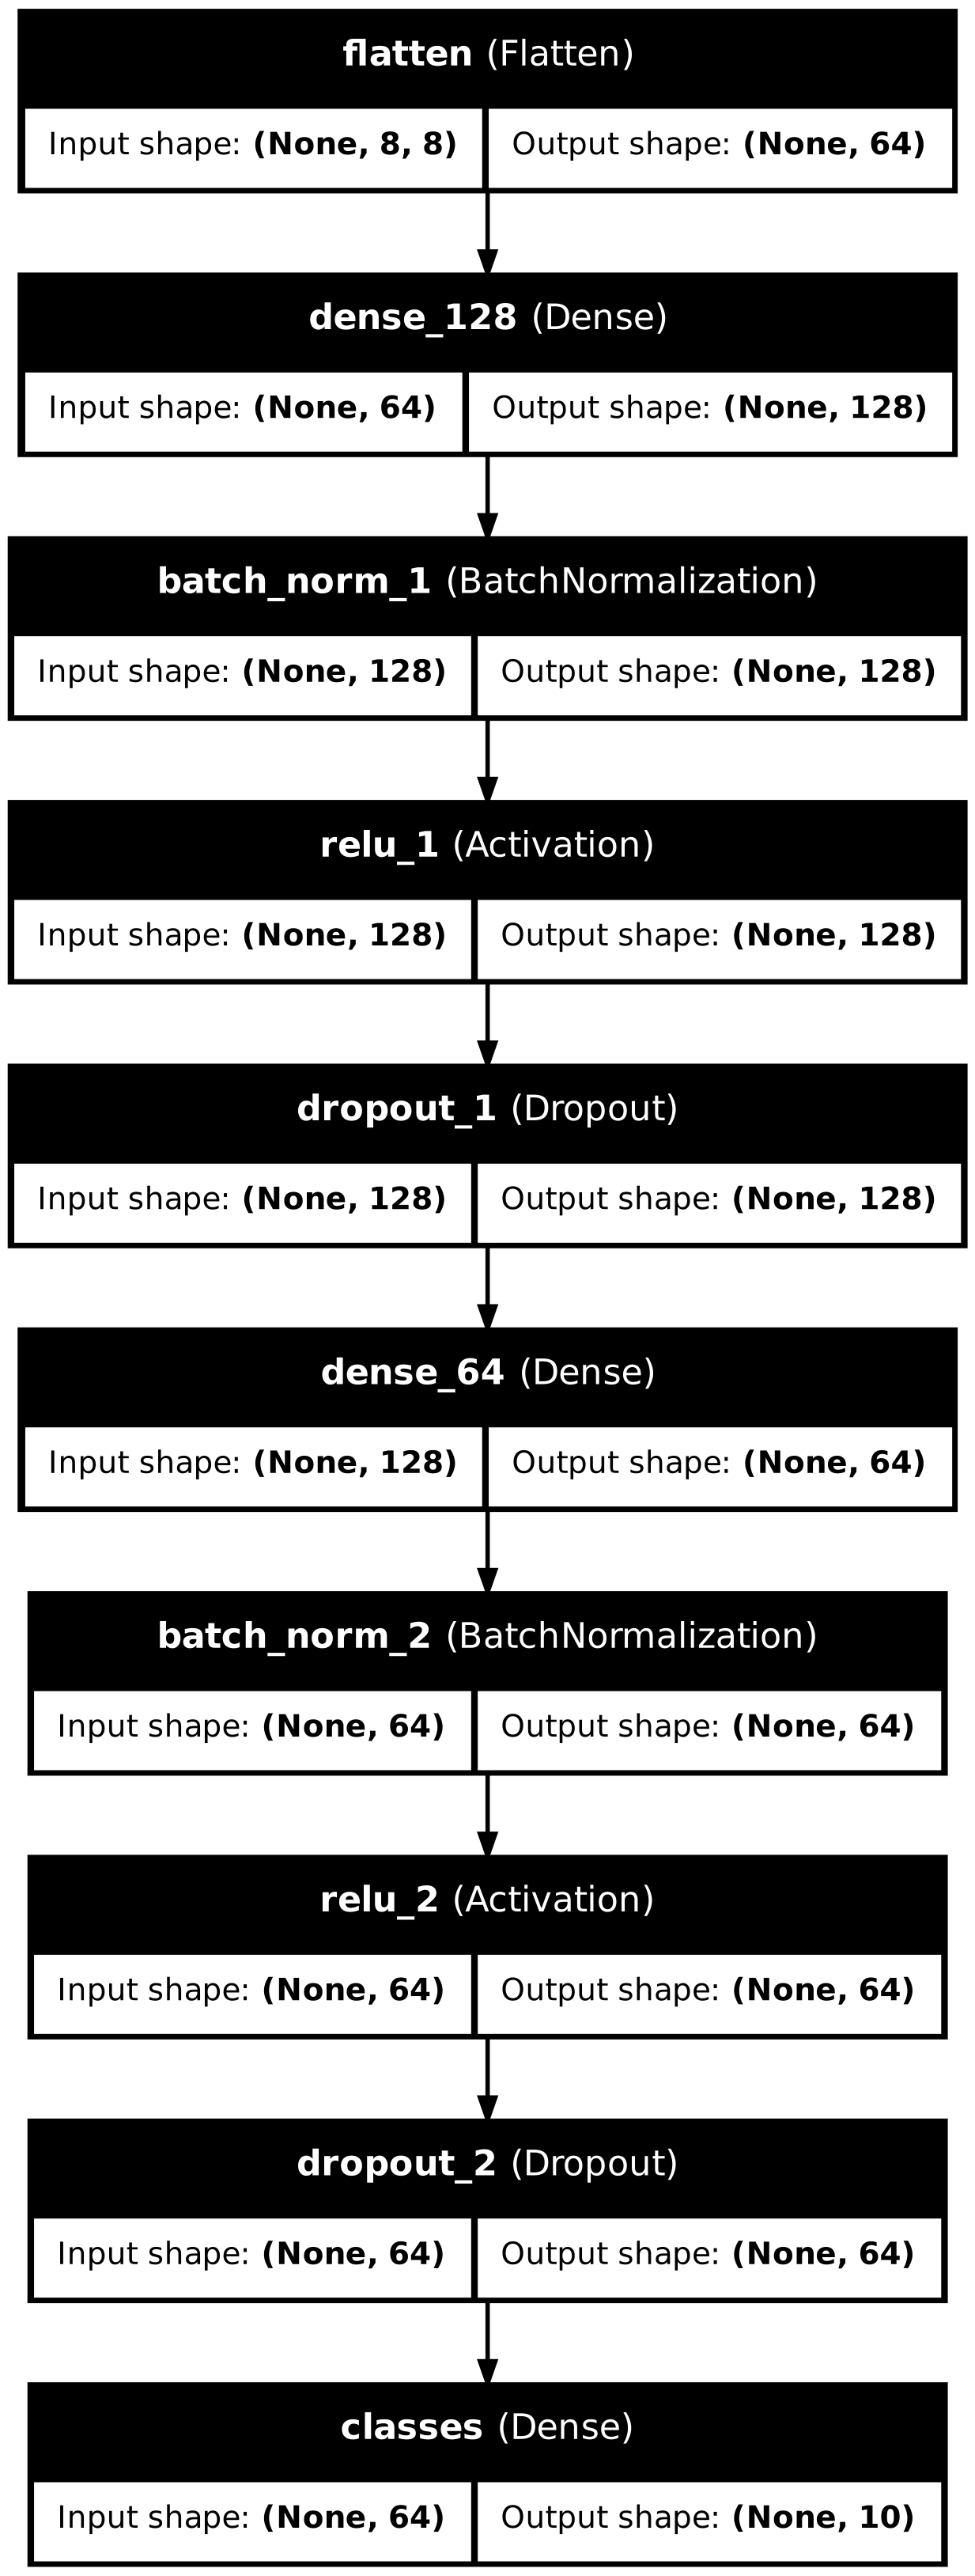

In [ ]:
# Графічна схема нової моделі (необов'язково, потребує Graphviz і pydot)
from IPython.display import Image, display
try:
    keras.utils.plot_model(student_model, to_file="student_mlp_architecture.png",
                           show_shapes=True, show_layer_names=True, rankdir="TB")
    display(Image(filename="student_mlp_architecture.png", width=380))
except Exception as exc:
    print("Графічна схема недоступна:", type(exc).__name__, str(exc)[:200])

### Крок 2. Скомпілюйте та навчіть модель

Оберіть оптимізатор `SGD(momentum=...)` **або** `AdamW`, налаштуйте `SparseCategoricalCrossentropy`, `accuracy`, `EarlyStopping` і збережіть історію в змінній **`student_history`**.

In [ ]:
student_model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=0.001, weight_decay=1e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

student_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

# Навчаємо лише на x_train; x_val — для контролю, x_test не використовується
student_history = student_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=25,
    batch_size=32,
    callbacks=[student_early_stopping],
    verbose=1,
)

student_epochs = len(student_history.history["loss"])
best_epoch = int(np.argmin(student_history.history["val_loss"])) + 1
print("Оптимізатор:", type(student_model.optimizer).__name__)
print("Фактична кількість епох:", student_epochs)
print(f"Найкраща епоха за val_loss: {best_epoch} "
      f"(val_loss = {min(student_history.history['val_loss']):.4f})")

Epoch 1/25


 1/36 ━━━━━━━━━━━━━━━━━━━━ 27s 794ms/step - accuracy: 0.1562 - loss: 2.7122

21/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2723 - loss: 2.1348   

36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3890 - loss: 1.8381 - val_accuracy: 0.7118 - val_loss: 1.8692


Epoch 2/25


 1/36 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7500 - loss: 1.1530

... (76 outputs left out)

Epoch 25/25


 1/36 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9688 - loss: 0.0677

36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9809 - loss: 0.0773 - val_accuracy: 0.9826 - val_loss: 0.0610


Оптимізатор: AdamW
Фактична кількість епох: 25
Найкраща епоха за val_loss: 25 (val_loss = 0.0610)


**Обґрунтування вибору оптимізатора.** Обрано **AdamW** (`learning_rate=0.001`, `weight_decay=1e-4`). Як і Adam, він адаптує крок для кожного параметра окремо, тому швидко й стабільно збігається без ручного підбору momentum і графіка швидкості навчання; це зручно для невеликого набору (1 149 навчальних прикладів) і обмеженого бюджету в 25 епох. Відмінність від Adam — **відокремлене зменшення ваг** (weight decay): ваги на кожному кроці трохи стягуються до нуля незалежно від градієнта. Це додаткова регуляризація для моделі, яка майже втричі більша за базову (17 802 параметри проти 6 762). Швидкість навчання 0,001 залишено такою самою, як у базовій моделі, щоб порівняння було коректним. Навчання тривало всі 25 епох: `val_loss` спадав аж до останньої епохи (0,0610), тож EarlyStopping не спрацював.

### Крок 3. Побудуйте криві навчання

Побудуйте два графіки: `loss` / `val_loss` і `accuracy` / `val_accuracy`. Порівняйте їхній перебіг та визначте, чи є ознаки перенавчання або недонавчання.

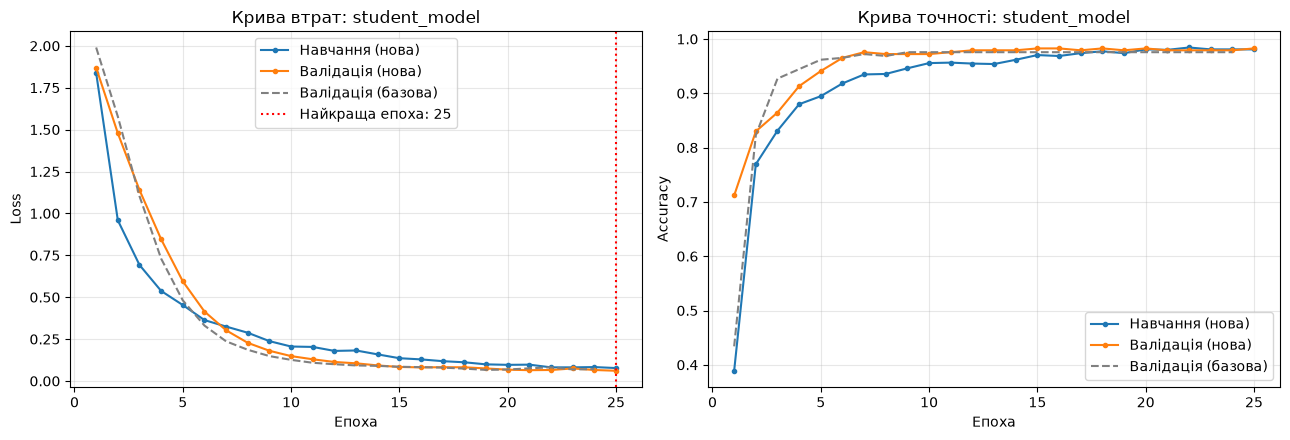

На найкращій епосі 25: loss = 0.0773, val_loss = 0.0610, accuracy = 0.9809, val_accuracy = 0.9826
Остання епоха 25: loss = 0.0773, val_loss = 0.0610, accuracy = 0.9809, val_accuracy = 0.9826


In [ ]:
student_epochs_done = np.arange(1, student_epochs + 1)
h = student_history.history
base_h = history.history

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(student_epochs_done, h["loss"], label="Навчання (нова)", marker="o", ms=3)
axes[0].plot(student_epochs_done, h["val_loss"], label="Валідація (нова)", marker="o", ms=3)
axes[0].plot(np.arange(1, len(base_h["val_loss"]) + 1), base_h["val_loss"],
             label="Валідація (базова)", linestyle="--", color="gray")
axes[0].axvline(best_epoch, color="red", linestyle=":", label=f"Найкраща епоха: {best_epoch}")
axes[0].set(title="Крива втрат: student_model", xlabel="Епоха", ylabel="Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(student_epochs_done, h["accuracy"], label="Навчання (нова)", marker="o", ms=3)
axes[1].plot(student_epochs_done, h["val_accuracy"], label="Валідація (нова)", marker="o", ms=3)
axes[1].plot(np.arange(1, len(base_h["val_accuracy"]) + 1), base_h["val_accuracy"],
             label="Валідація (базова)", linestyle="--", color="gray")
axes[1].set(title="Крива точності: student_model", xlabel="Епоха", ylabel="Accuracy")
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

i = best_epoch - 1
print(f"На найкращій епосі {best_epoch}: loss = {h['loss'][i]:.4f}, val_loss = {h['val_loss'][i]:.4f}, "
      f"accuracy = {h['accuracy'][i]:.4f}, val_accuracy = {h['val_accuracy'][i]:.4f}")
print(f"Остання епоха {student_epochs}: loss = {h['loss'][-1]:.4f}, val_loss = {h['val_loss'][-1]:.4f}, "
      f"accuracy = {h['accuracy'][-1]:.4f}, val_accuracy = {h['val_accuracy'][-1]:.4f}")

**Аналіз кривих навчання.** Обидві криві втрат швидко спадають протягом перших 7–8 епох, а далі плавно наближаються до мінімуму: на 25-й епосі `loss` = 0,077, `val_loss` = 0,061. Ознак **перенавчання немає**: валідаційні втрати не зростають, а навчальна і валідаційна точність майже збігаються (0,981 і 0,983). На більшості епох валідаційна точність навіть трохи вища за навчальну. Це очікуваний ефект `Dropout(0.3)` і BatchNormalization: під час навчання частина нейронів вимкнена, а під час валідації модель працює повністю. **Недонавчання** теж немає, адже точність понад 98 %. Водночас `val_loss` усе ще повільно зменшувався на останній епосі, тож ще кілька епох могли б дати невелике покращення. Порівняно з базовою моделлю (сіра пунктирна лінія) нова модель на перших епохах навчається трохи повільніше через сильніший Dropout, але після 7-ї епохи має практично таку саму валідаційну точність (≈ 0,97–0,98).

### Крок 4. Перевірте якість на тестовій вибірці

Виконайте `evaluate()` для **`student_model`**, отримайте класи з `predict()`, виведіть accuracy і матрицю помилок. Порівняйте тестову точність із **`test_accuracy`** базової моделі.

Тестові втрати student_model: 0.0675
Тестова точність student_model: 98.33%
Правильно: 354 із 360


,Параметрів,Епох,Test loss,Test accuracy,Помилок на тесті
Модель,,,,,
"Базова model (64-32, Adam, Dropout 0.2)",6762,24,0.0679,0.9778,8
"student_model (128-64, AdamW, Dropout 0.3)",17802,25,0.0675,0.9833,6



              precision    recall  f1-score   support

           0      0.973     1.000     0.986        36
           1      0.944     0.944     0.944        36
           2      1.000     1.000     1.000        35
           3      1.000     1.000     1.000        37
           4      1.000     1.000     1.000        36
           5      0.974     1.000     0.987        37
           6      0.972     0.972     0.972        36
           7      0.973     1.000     0.986        36
           8      1.000     0.943     0.971        35
           9      1.000     0.972     0.986        36

    accuracy                          0.983       360
   macro avg      0.984     0.983     0.983       360
weighted avg      0.984     0.983     0.983       360



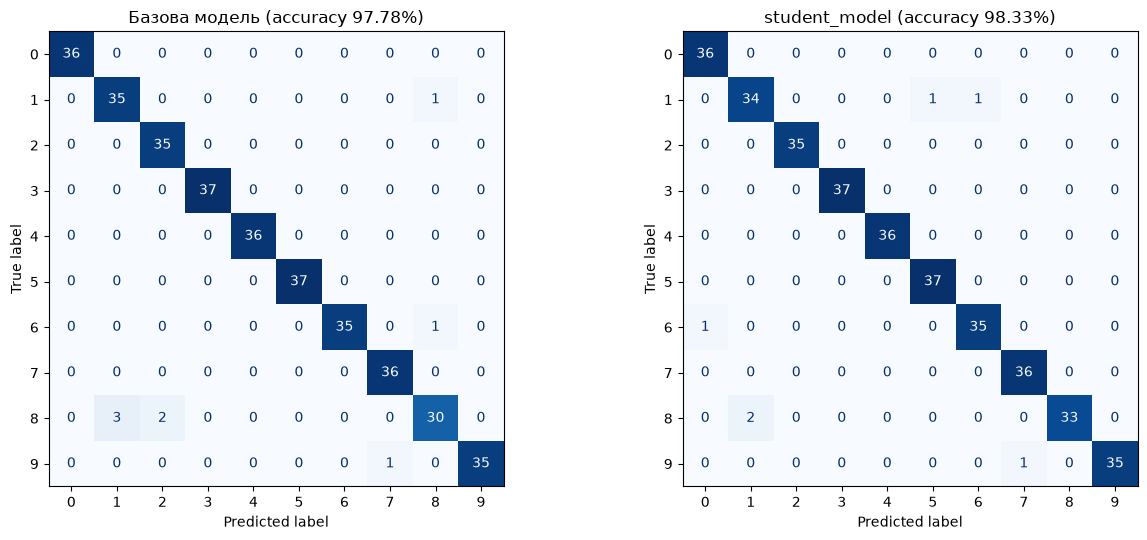

In [ ]:
student_test_loss, student_test_accuracy = student_model.evaluate(x_test, y_test, verbose=0)
student_probabilities = student_model.predict(x_test, verbose=0)
student_predicted = np.argmax(student_probabilities, axis=1)
student_confidence = student_probabilities.max(axis=1)

print(f"Тестові втрати student_model: {student_test_loss:.4f}")
print(f"Тестова точність student_model: {student_test_accuracy:.2%}")
print(f"Правильно: {(student_predicted == y_test).sum()} із {len(y_test)}")

import pandas as pd

comparison = pd.DataFrame({
    "Модель": ["Базова model (64-32, Adam, Dropout 0.2)", "student_model (128-64, AdamW, Dropout 0.3)"],
    "Параметрів": [model.count_params(), student_model.count_params()],
    "Епох": [len(history.history["loss"]), student_epochs],
    "Test loss": [test_loss, student_test_loss],
    "Test accuracy": [test_accuracy, student_test_accuracy],
    "Помилок на тесті": [int((predicted_classes != y_test).sum()), int((student_predicted != y_test).sum())],
}).set_index("Модель")
display(comparison.round(4))

print()
print(classification_report(y_test, student_predicted, digits=3, zero_division=0))

student_matrix = confusion_matrix(y_test, student_predicted, labels=np.arange(10))
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, mtx, title in zip(axes, [matrix, student_matrix],
                          [f"Базова модель (accuracy {test_accuracy:.2%})",
                           f"student_model (accuracy {student_test_accuracy:.2%})"]):
    ConfusionMatrixDisplay(confusion_matrix=mtx, display_labels=np.arange(10)).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [ ]:
# Які пари класів плутає нова модель (справжній → прогнозований)
errors = [(int(t), int(p)) for t, p in zip(y_test, student_predicted) if t != p]
if errors:
    from collections import Counter
    for (t, p), cnt in Counter(errors).most_common():
        print(f"Справжній {t} → прогноз {p}: {cnt} раз(и)")
else:
    print("Помилок на тестовій вибірці немає.")

Справжній 8 → прогноз 1: 2 раз(и)
Справжній 1 → прогноз 6: 1 раз(и)
Справжній 6 → прогноз 0: 1 раз(и)
Справжній 9 → прогноз 7: 1 раз(и)
Справжній 1 → прогноз 5: 1 раз(и)


### Крок 5. Візуалізуйте щонайменше 12 прогнозів

Покажіть тестові зображення з підписами **«Справжній клас»** та **«Прогнозований клас»**. Правильні й помилкові результати виділіть різними кольорами. За наявності помилок додайте кілька помилкових прикладів.

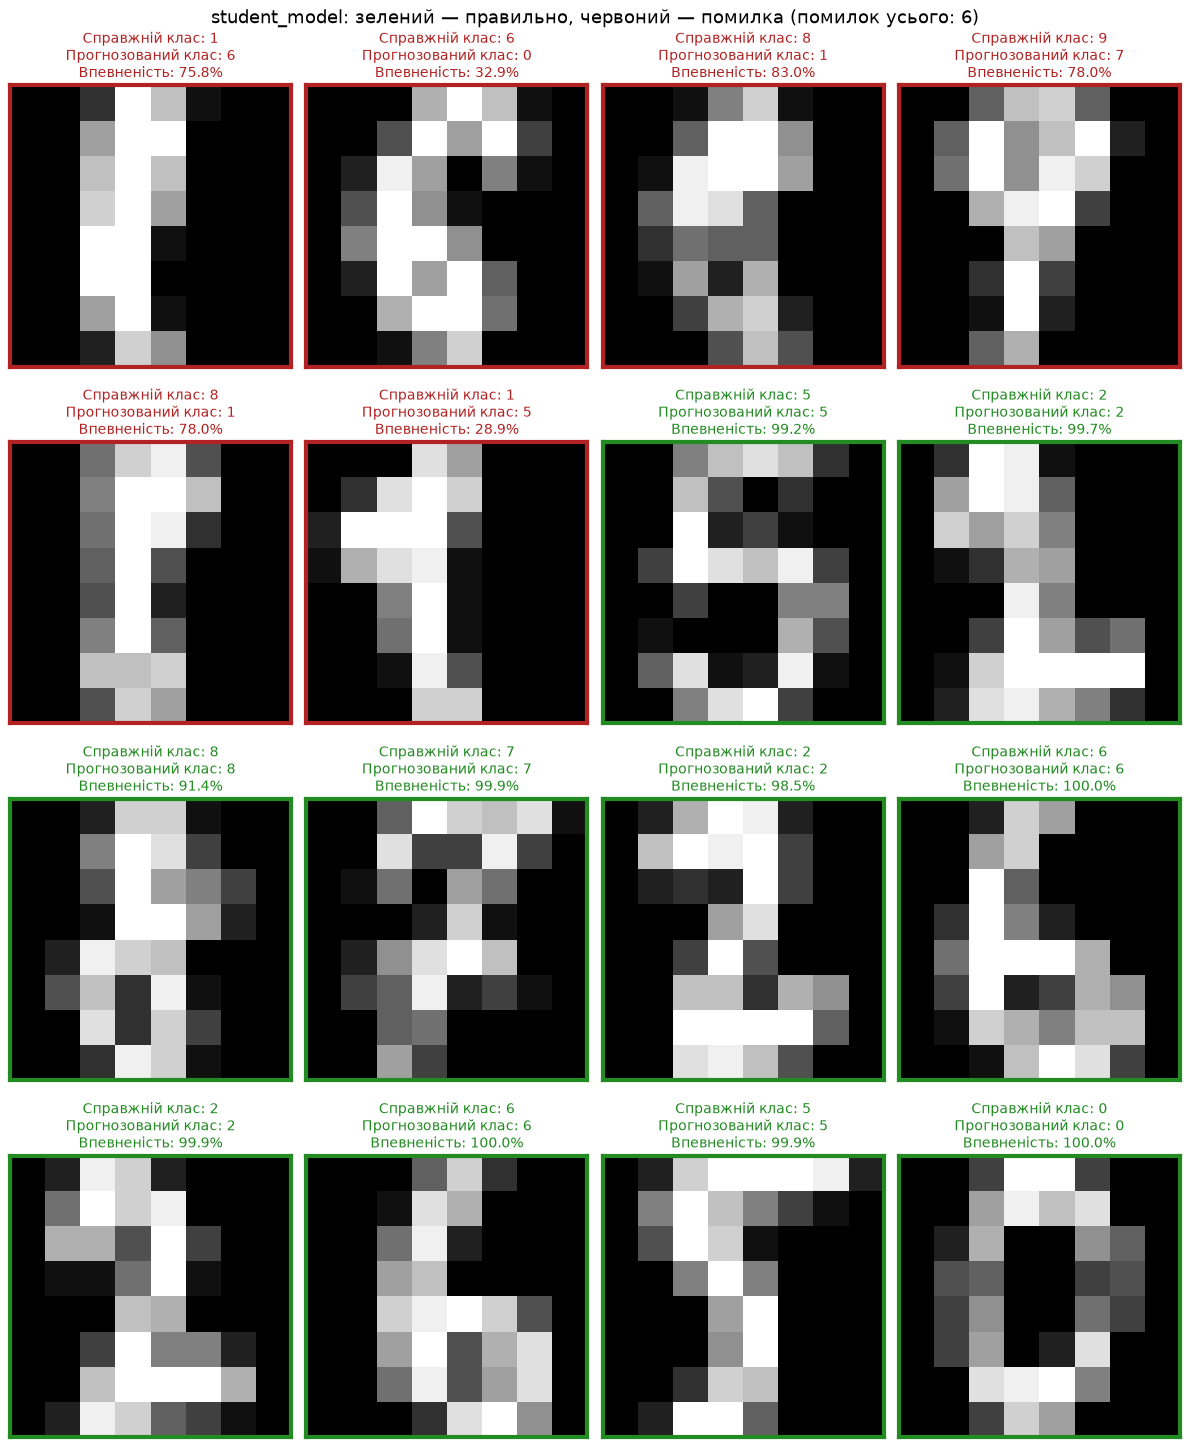

In [ ]:
student_correct_idx = np.flatnonzero(student_predicted == y_test)
student_wrong_idx = np.flatnonzero(student_predicted != y_test)

# Усі помилкові приклади (до 8), решту — правильні; разом 16 зображень
selected_student = list(student_wrong_idx[:8])
selected_student += list(student_correct_idx[:16 - len(selected_student)])

fig, axes = plt.subplots(4, 4, figsize=(12, 15))
for ax, idx in zip(axes.flat, selected_student):
    is_correct = student_predicted[idx] == y_test[idx]
    color = "forestgreen" if is_correct else "firebrick"
    ax.imshow(x_test[idx], cmap="gray", vmin=0, vmax=1)
    ax.set_title(
        f"Справжній клас: {y_test[idx]}\nПрогнозований клас: {student_predicted[idx]}\n"
        f"Впевненість: {student_confidence[idx]:.1%}",
        color=color, fontsize=10,
    )
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor(color)
        spine.set_linewidth(3)
plt.suptitle(f"student_model: зелений — правильно, червоний — помилка "
             f"(помилок усього: {len(student_wrong_idx)})", fontsize=13)
plt.tight_layout()
plt.show()

### Крок 6. Експериментуйте з одним параметром

Змініть **один** параметр нового варіанта (наприклад, `Dropout rate` або `learning_rate`), повторіть навчання та порівняйте результати. Поясніть, чому для коректного порівняння інші умови доцільно залишати сталими.

,Епох,Найкраща епоха,train acc,val loss,val acc,train-val gap (acc),test loss,test acc,помилок
Варіант,,,,,,,,,
Dropout 0.30,25,25,0.9809,0.0610,0.9826,-0.0018,0.0675,0.9833,6
Dropout 0.10,25,22,1.0000,0.0512,0.9861,0.0139,0.0632,0.9833,6


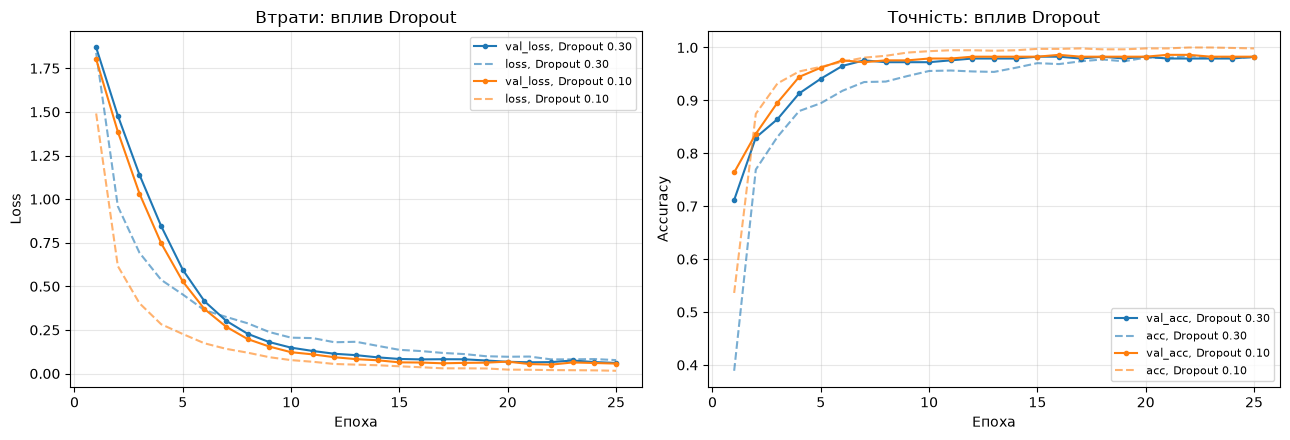

In [ ]:
# Експеримент: змінюємо ЛИШЕ Dropout rate 0.30 → 0.10.
# Архітектура, оптимізатор, learning_rate, batch_size, EarlyStopping і seed — ті самі.
EXPERIMENT_DROPOUT = 0.10

keras.utils.set_random_seed(42)   # той самий seed, що й для student_model
experiment_model = build_student_model(dropout_rate=EXPERIMENT_DROPOUT, name="student_mlp_dropout_010")
experiment_model.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=0.001, weight_decay=1e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)
experiment_history = experiment_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=25,
    batch_size=32,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)],
    verbose=0,
)
exp_test_loss, exp_test_accuracy = experiment_model.evaluate(x_test, y_test, verbose=0)
exp_predicted = np.argmax(experiment_model.predict(x_test, verbose=0), axis=1)


def summarize(name, hist, t_loss, t_acc, preds):
    hh = hist.history
    b = int(np.argmin(hh["val_loss"]))
    return {
        "Варіант": name,
        "Епох": len(hh["loss"]),
        "Найкраща епоха": b + 1,
        "train acc": round(hh["accuracy"][b], 4),
        "val loss": round(hh["val_loss"][b], 4),
        "val acc": round(hh["val_accuracy"][b], 4),
        "train-val gap (acc)": round(hh["accuracy"][b] - hh["val_accuracy"][b], 4),
        "test loss": round(t_loss, 4),
        "test acc": round(t_acc, 4),
        "помилок": int((preds != y_test).sum()),
    }


rows = [
    summarize("Dropout 0.30", student_history, student_test_loss, student_test_accuracy, student_predicted),
    summarize(f"Dropout {EXPERIMENT_DROPOUT:.2f}", experiment_history, exp_test_loss, exp_test_accuracy, exp_predicted),
]
display(pd.DataFrame(rows).set_index("Варіант"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for hist, label in [(student_history, "Dropout 0.30"), (experiment_history, f"Dropout {EXPERIMENT_DROPOUT:.2f}")]:
    ep = np.arange(1, len(hist.history["loss"]) + 1)
    line, = axes[0].plot(ep, hist.history["val_loss"], marker="o", ms=3, label=f"val_loss, {label}")
    axes[0].plot(ep, hist.history["loss"], linestyle="--", color=line.get_color(), alpha=0.6,
                 label=f"loss, {label}")
    line, = axes[1].plot(ep, hist.history["val_accuracy"], marker="o", ms=3, label=f"val_acc, {label}")
    axes[1].plot(ep, hist.history["accuracy"], linestyle="--", color=line.get_color(), alpha=0.6,
                 label=f"acc, {label}")
axes[0].set(title="Втрати: вплив Dropout", xlabel="Епоха", ylabel="Loss")
axes[1].set(title="Точність: вплив Dropout", xlabel="Епоха", ylabel="Accuracy")
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Висновок до експерименту.** Змінено лише один параметр — `Dropout rate` з 0,30 на 0,10. Seed, архітектура, оптимізатор, `learning_rate`, `batch_size`, кількість епох та EarlyStopping залишились однаковими. Зі слабшим Dropout модель навчається швидше і точніше запам'ятовує навчальну вибірку: train accuracy досягла 1,000, `val_loss` зменшився з 0,0610 до 0,0512, а val accuracy зросла з 0,983 до 0,986. Тестова точність однакова (98,33 %, по 6 помилок), лише тестові втрати трохи нижчі (0,0632 проти 0,0675). Водночас з'явився розрив між навчальною та валідаційною точністю (1,4 п. п. проти −0,2 п. п. при Dropout 0,3) — перша ознака схильності до перенавчання, яка на такому малому наборі ще не встигла нашкодити. Інші умови треба залишати сталими, бо лише тоді різницю в результатах можна пояснити саме зміненим параметром. Якби одночасно змінювались, наприклад, швидкість навчання чи початкові ваги (seed), не можна було б сказати, який чинник вплинув на результат. Через невеликий розмір тестової вибірки (360 зображень) різниця в 1–2 помилки статистично незначуща, тому висновок про Dropout варто робити передусім за валідаційними втратами і кривими.

### Висновок студента

Додайте в наступну порожню комірку Markdown короткий висновок (5–8 речень): яка з моделей показала кращу тестову якість, що демонструють криві навчання, які класи було складніше розпізнавати та як вплинула змінена гіперпараметрична настройка.

### Висновок

Нова модель `student_model` (Flatten → 128 → 64 → 10, BatchNormalization, `Dropout(0.3)`, AdamW) показала **кращу тестову якість**, ніж базова модель: точність 98,33 % проти 97,78 % (6 помилок проти 8 із 360) при майже однакових тестових втратах (0,0675 і 0,0679). Перевага невелика, бо обидві моделі вже майже ідеально розпізнають прості зображення 8×8, а нова має майже втричі більше параметрів (17 802 проти 6 762). Криві навчання показують стабільне навчання без перенавчання: `val_loss` спадав до останньої 25-ї епохи, а навчальна й валідаційна точність практично збігаються (0,981 і 0,983) завдяки регуляризації Dropout, BatchNormalization та weight decay. Найважче моделі розпізнавати цифри **1 і 8**: їхній recall найнижчий (0,944 і 0,943), двічі вісімку передбачено як одиницю, а одиниці плутались із 5 і 6. У базовій моделі найбільше помилок теж було на цифрі 8 (recall 0,857). Експеримент зі зменшенням Dropout з 0,3 до 0,1 знизив валідаційні втрати (0,0512 проти 0,0610), але тестова точність не змінилась (98,33 %), а навчальна точність досягла 100 %, тобто зі слабшою регуляризацією модель більше підлаштовується під навчальні дані. Отже, для цього набору обидва значення Dropout прийнятні; значення 0,3 надійніше захищає від перенавчання, а значення 0,1 трохи пришвидшує навчання.